## Customer Cohort & Churn Analytics: Telecom Retention, Driver Quantification & Risk Scoring ##

### Phase 1: Data Ingestion & Schema Exploration

In [78]:
# Import required libraries
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns

In [79]:
# Set clean display & chart defaults
pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

In [80]:
# Load dataset
df = pd.read_csv(r"C:\Users\JaiAkash\Downloads\telco_customer_churn.csv")
print(f'Dataset loaded: {df.shape[0]:,} rows x {df.shape[1]} columns')
df.head(7)

Dataset loaded: 7,043 rows x 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,Yes,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No


In [81]:
# Inspect column data types and non-null counts
print('\nColumn Data Types & Non-Null Counts:')
print(df.info())


Column Data Types & Non-Null Counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  Pape

### Data Interpretation Summary

##### Dataset Scale: 
The dataset contains 7,043 customer records across 21 columns, covering demographics (gender, SeniorCitizen, Partner, Dependents), tenure and billing (tenure, Contract, PaperlessBilling, PaymentMethod, MonthlyCharges, TotalCharges), service add-ons (PhoneService, InternetService, TechSupport, OnlineSecurity, streaming services), and churn status (Churn).

##### Schema Anomaly Detected: 
TotalCharges loads as an object (string) column rather than numeric due to blank/whitespace entries on accounts with tenure = 0, requiring numeric type coercion before financial calculations.

### Phase 2: Data Cleaning, Feature Engineering & Baseline Churn KPIs

In [112]:
# Convert TotalCharges to numeric and check blank rows
df['TotalCharges_num'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print('Blank TotalCharges count:', df ['TotalCharges_num'].isna().sum())
print('Tenure for blank rows   :', df.loc[df ['TotalCharges_num'].isna(), 'tenure'].value_counts().to_dict())

Blank TotalCharges count: 11
Tenure for blank rows   : {0: 11}


In [111]:
# Impute 0.0 for new customers (tenure == 0) prior to first billed cycle
df['TotalCharges_clean'] = df['TotalCharges_num'].fillna(0.0)

In [110]:
# Create binary churn and retention flags
df['churn_flag'] = (df['Churn'] == 'Yes').astype(int)
df['retained_flag'] = 1 - df['churn_flag']

In [109]:
# Calculate baseline churn and retention KPIs
total_cust = len(df)
churned_cust = df['churn_flag'].sum()
retained_cust = df['retained_flag'].sum()
baseline_churn_rate = churned_cust / total_cust * 100
baseline_retained_rate = retained_cust / total_cust * 100

print(f'Total Customers : {total_cust:,}')
print(f'Churned         : {churned_cust:,} ({baseline_churn_rate:.2f}%)')
print(f'Retained        : {retained_cust:,} ({baseline_retained_rate:.2f}%)')

Total Customers : 7,043
Churned         : 1,869 (26.54%)
Retained        : 5,174 (73.46%)


### Data Interpretation Summary

##### Missing Value Resolution: 

All 11 non-numeric TotalCharges rows belong to customers with tenure = 0 (prior to their first full billed cycle). Imputing 0.0 retains all 7,043 records cleanly.

##### Baseline Metrics: 
    
Out of 7,043 customers, 1,869 churned and 5,174 were retained, setting a 26.54% baseline churn rate and a 73.46% baseline retention rate.

### Phase 3: Cohort Segmentation & Retention Matrix Analysis ###

In [105]:
# Create 12-month tenure cohorts
bins_12 = [-1, 12, 24, 36, 48, 60, 72]
labels = ['0-12m', '13-24m', '25-36m', '36-48m', '49-60m', '61-72m']
df['tenure-cohort'] = pd.cut(df['tenure'],bins=bins_12, labels=labels_12)


In [108]:
# Summarize churn and retention by tenure cohort
tenure_summary = df.groupby('tenure_cohort', observed=False).agg(
    customers=('customerID', 'count'),
    churned=('churn_flag', 'sum'),
    retained=('retained_flag', 'sum'),
    avg_monthly=('MonthlyCharges', 'mean'),
)

tenure_summary['churn_rate_%'] = (tenure_summary['churned'] / tenure_summary['customers'] * 100).round(2)
tenure_summary['retention_rate_%'] = (tenure_summary['retained'] / tenure_summary['customers'] * 100).round(2)
tenure_summary['avg_monthly'] = tenure_summary['avg_monthly'].round(2)

display(tenure_summary)

,customers,churned,retained,avg_monthly,churn_rate_%,retention_rate_%
tenure_cohort,,,,,,
0-12m,2186,1037,1149,56.10,47.44,52.56
13-24m,1024,294,730,61.36,28.71,71.29
25-36m,832,180,652,65.58,21.63,78.37
37-48m,762,145,617,66.32,19.03,80.97
49-60m,832,120,712,70.55,14.42,85.58
61-72m,1407,93,1314,75.95,6.61,93.39


In [99]:
# Summarize churn and retention by contract type
contract_summary = df.groupby('Contract') .agg(
    customers=('customerID', 'count'),
    churned=('churn_flag', 'sum'),
    avg_tenure=('tenure','mean'),
    avg_monthly=('MonthlyCharges','mean'),)

contract_summary['churn_rate_%'] = (contract_summary['churned'] / contract_summary['customers'] * 100).round(2)
contract_summary['retention_rate_%'] = (100 - contract_summary['churn_rate_%']).round(2)
display(contract_summary)


,customers,churned,avg_tenure,avg_monthly,churn_rate_%,retention_rate_%
Contract,,,,,,
Month-to-month,3875,1655,18.036645,66.398490,42.71,57.29
One year,1473,166,42.044807,65.048608,11.27,88.73
Two year,1695,48,56.735103,60.770413,2.83,97.17


In [100]:
# Summarize churn and retention by payment method
payment_summary = df.groupby('PaymentMethod').agg(
    customers=('customerID', 'count'),
    churned=('churn_flag', 'sum'),
    avg_monthly=('MonthlyCharges', 'mean'),
)
payment_summary['churn_rate_%'] = (payment_summary['churned'] / payment_summary['customers'] * 100).round(2)
payment_summary['retention_rate_%'] = (100 - payment_summary['churn_rate_%']).round(2)
display(payment_summary.sort_values('churn_rate_%', ascending=False))

,customers,churned,avg_monthly,churn_rate_%,retention_rate_%
PaymentMethod,,,,,
Electronic check,2365,1071,76.255814,45.29,54.71
Mailed check,1612,308,43.917060,19.11,80.89
Bank transfer (automatic),1544,258,67.192649,16.71,83.29
Credit card (automatic),1522,232,66.512385,15.24,84.76


In [104]:
# Segment monthly charges into four quartiles
df['charge_tier'] = pd.qcut(
    df['MonthlyCharges'],
    q=4,
    labels=['Q1: Low ($18.25-$35.50)', 'Q2: Low-Mid ($35.50-$70.35)', 'Q3: Upper-Mid ($70.35-$89.85)', 'Q4: High ($89.85-$118.75)'],
)

charge_summary = df.groupby('charge_tier', observed=False) .agg(
    customers=('customerID', 'count'),
    churned=('churn_flag', 'sum'),
    avg_tenure=('tenure','mean'),)

charge_summary['churn_rate_%'] = (charge_summary['churned'] / charge_summary['customers'] * 100).round(2)
display(charge_summary)

,customers,churned,avg_tenure,churn_rate_%
charge_tier,,,,
Q1: Low ($18.25-$35.50),1762,198,28.542565,11.24
Q2: Low-Mid ($35.50-$70.35),1766,434,26.560023,24.58
Q3: Upper-Mid ($70.35-$89.85),1757,659,29.672168,37.51
Q4: High ($89.85-$118.75),1758,578,44.743458,32.88


In [107]:
# Ensure tenure_cohort exists with matching labels
bins_12 = [-1, 12, 24, 36, 48, 60, 72]
labels_12 = ['0-12m', '13-24m', '25-36m', '37-48m', '49-60m', '61-72m']
df['tenure_cohort'] = pd.cut(df['tenure'], bins=bins_12, labels=labels_12)


# Build Cohort Retention Matrix (% Retained by Tenure Cohort x Contract)
retention_matrix = (
    df.pivot_table(
        index='tenure_cohort',
        columns='Contract',
        values='retained_flag',
        aggfunc='mean',
        observed=False,
    )[['Month-to-month', 'One year', 'Two year']] * 100
)

display(retention_matrix.round(2))

Contract,Month-to-month,One year,Two year
tenure_cohort,,,
0-12m,48.65,89.52,100.00
13-24m,62.28,91.88,100.00
25-36m,67.49,92.00,97.92
37-48m,66.46,86.94,97.75
49-60m,72.22,86.29,96.03
61-72m,77.78,87.86,96.86


### Data Interpretation Summary

##### Tenure Vintage Pattern: 

Churn is highest in the first year (0–12m at 47.44%, or 1,037 / 2,186) and declines steadily across longer tenures (28.71% in 13-24m, 21.63% in 25-36m, 19.03% in 37-48m, 14.42% in 49-60m, and 6.61% in 61-72m).

##### Contract Commitment Impact: 

Month-to-month contracts represent 1,655 of 1,869 churned customers (88.55%) with a 42.71% churn rate (48.65% retention in 0-12m), compared to 11.27% for One year and 2.83% for Two year contracts.

##### Payment Method & Price Tier Drivers: 

Electronic check payers experience 45.29% churn (1,071 / 2,365), roughly triple automatic credit card (15.24%) and bank transfer (16.71%) churn rates. Upper-mid monthly charges (Q3: $70.35–$89.85) record the highest churn rate across price quartiles at 37.51%.

### Phase 4: High-Risk Driver Segmentation & Visual Heatmaps

In [88]:
# Analyze churn across InternetService, TechSupport, and OnlineSecurity
service_risk = (
    df.groupby(['InternetService', 'TechSupport', 'OnlineSecurity'])
    .agg(
        customers=('customerID', 'count'),
        churned=('churn_flag', 'sum'),
        avg_monthly=('MonthlyCharges', 'mean'),)
    .assign(
        churn_rate_pct=lambda d: (d['churned'] / d['customers'] * 100).round(2),
        retention_rate_pct=lambda d: (100 - d['churned'] / d['customers'] * 100).round(2),
    )
    .sort_values('churn_rate_pct', ascending=False)
)
display(service_risk)

customers  churned  \
InternetService TechSupport         OnlineSecurity                            
Fiber optic     No                  No                        1765      971   
DSL             No                  No                         788      279   
Fiber optic     Yes                 No                         492      143   
                No                  Yes                        465      130   
DSL             Yes                 No                         453       68   
                No                  Yes                        455       66   
Fiber optic     Yes                 Yes                        374       53   
No              No internet service No internet service       1526      113   
DSL             Yes                 Yes                        725       46   

                                                         avg_monthly  \
InternetService TechSupport         OnlineSecurity                     
Fiber optic     No                  No                     86.098442   
DSL             No                  No                     47.511612   
Fiber optic     Yes                 No                     97.712703   
                No                  Yes                    93.984194   
DSL             Yes                 No                     60.257837   
                No                  Yes                    56.997802   
Fiber optic     Yes                 Yes                   105.730882   
No              No internet service No internet service    21.079194   
DSL             Yes                 Yes                    68.959172   

                                                         churn_rate_pct  \
InternetService TechSupport         OnlineSecurity                        
Fiber optic     No                  No                            55.01   
DSL             No                  No                            35.41   
Fiber optic     Yes                 No                            29.07   
                No                  Yes                           27.96   
DSL             Yes                 No                            15.01   
                No                  Yes                           14.51   
Fiber optic     Yes                 Yes                           14.17   
No              No internet service No internet service            7.40   
DSL             Yes                 Yes                            6.34   

                                                         retention_rate_pct  
InternetService TechSupport         OnlineSecurity                           
Fiber optic     No                  No                                44.99  
DSL             No                  No                                64.59  
Fiber optic     Yes                 No                                70.93  
                No                  Yes                               72.04  
DSL             Yes                 No                                84.99  
                No                  Yes                               85.49  
Fiber optic     Yes                 Yes                               85.83  
No              No internet service No internet service               92.60  
DSL             Yes                 Yes                               93.66

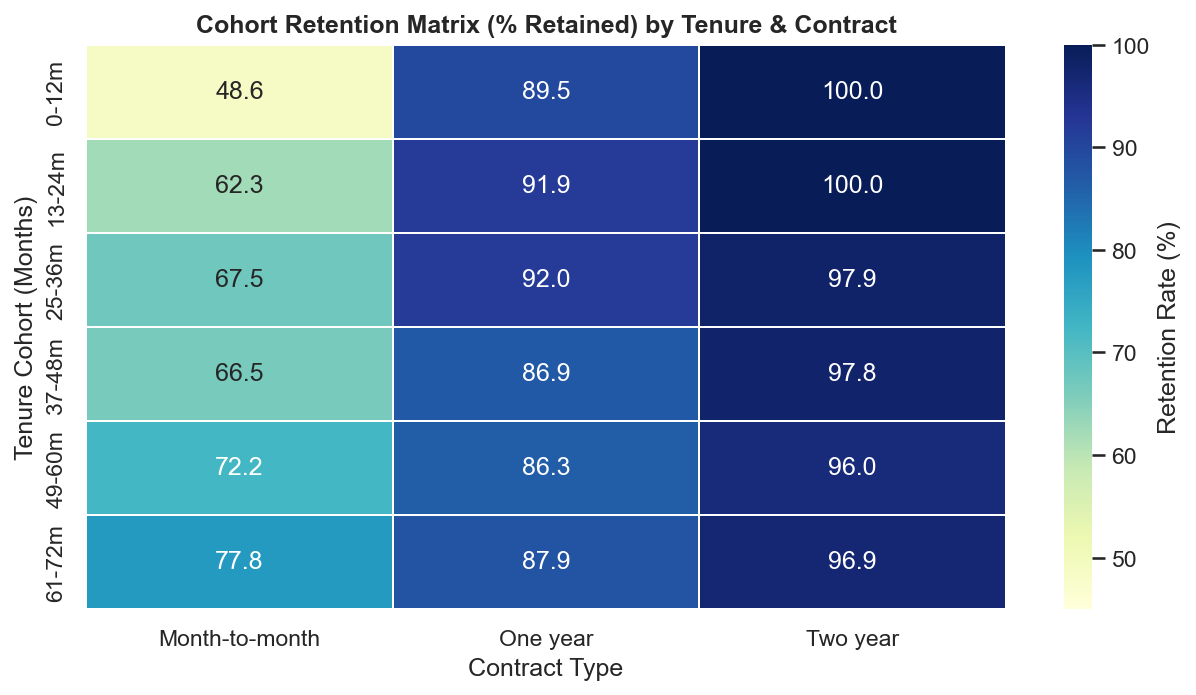

In [89]:
# Plot Cohort Retention Matrix heatmap (Seaborn)
fig, ax = plt.subplots(figsize=(8.5, 4.8), dpi=150)
sns.heatmap(
    retention_matrix,
    annot=True,
    fmt='.1f',
    cmap='YlGnBu',
    vmin=45,
    vmax=100,
    linewidths=0.8,
    cbar_kws={'label': 'Retention Rate (%)'},
    ax=ax,
)
ax.set_title('Cohort Retention Matrix (% Retained) by Tenure & Contract', fontweight='bold')
ax.set_xlabel('Contract Type')
ax.set_ylabel('Tenure Cohort (Months)')
plt.tight_layout()
plt.savefig('cohort_retention_matrix.png', dpi=150)
plt.show()

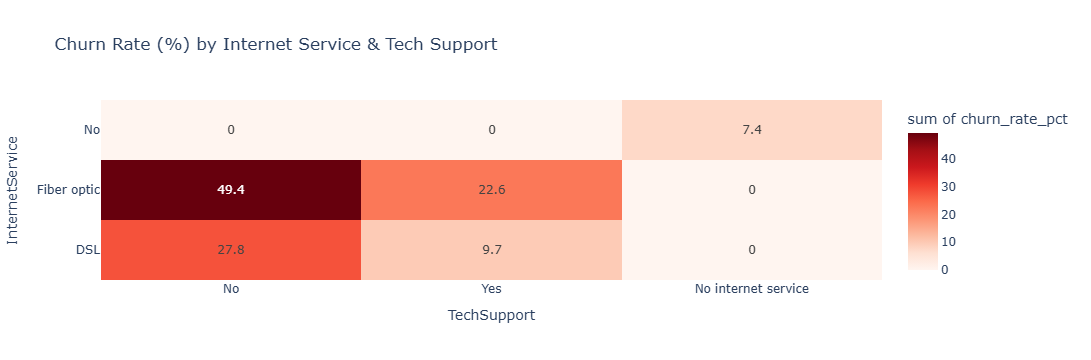

In [90]:
# Plot interactive Service-Tier Churn heatmap (Plotly)
svc_heatmap = (
    df.groupby(['InternetService', 'TechSupport'])['churn_flag']
    .agg(churn_rate_pct=lambda s: round(s.mean() * 100, 1), customers='count')
    .reset_index()
)
fig_px = px.density_heatmap(
    svc_heatmap,
    x='TechSupport',
    y='InternetService',
    z='churn_rate_pct',
    text_auto=True,
    color_continuous_scale='Reds',
    title='Churn Rate (%) by Internet Service & Tech Support',
)
fig_px.show()

### Data Interpretation Summary

##### Fiber Optic Without Support/Security: 

Fiber optic customers lacking both TechSupport and OnlineSecurity (1,765 customers, avg. monthly charge $86.10) have a 55.01% churn rate (971 churned), climbing to 57.52% among Month-to-month Fiber users without tech support.

##### Add-On Retention Effect: 

Fiber optic subscribers with both TechSupport and OnlineSecurity churn at just 14.17% (53 / 374) despite a higher average monthly charge ($105.73), demonstrating that support and security add-ons strongly reinforce retention.

### Phase 5: Churn Probability Scoring, Revenue-at-Risk & Retention Exports

In [91]:
# Import scikit-learn modeling utilities
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.model_selection import train_test_split

In [92]:
# Prepare feature matrix and binary target
features = [
    'tenure',
    'MonthlyCharges',
    'SeniorCitizen',
    'Contract',
    'PaymentMethod',
    'InternetService',
    'TechSupport',
    'OnlineSecurity',
    'PaperlessBilling',
]

X = pd.get_dummies(df[features], drop_first=True)
y = df['churn_flag']

In [93]:
# Split data and train Logistic Regression model
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

model = LogisticRegression(max_iter=2000)
model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,2000
,multi_class,'deprecated'


In [94]:
# Evaluate validation accuracy and ROC-AUC
test_probs = model.predict_proba(X_test)[:, 1]
test_preds = (test_probs >= 0.5).astype(int)
print(f'Validation Accuracy : {accuracy_score(y_test, test_preds)*100:.2f}%')
print(f'Validation ROC-AUC  : {roc_auc_score(y_test, test_probs):.4f}')

Validation Accuracy : 79.63%
Validation ROC-AUC  : 0.8368


In [95]:
# Score churn probability, revenue at risk, and risk quartiles
df['churn_prob'] = model.predict_proba(X)[:, 1]
df['expected_monthly_rev_at_risk'] = df['MonthlyCharges'] * df['churn_prob']
df['risk_tier'] = pd.qcut(
    df['churn_prob'],
    q=4,
    labels=['Low Risk (Q1)', 'Moderate Risk (Q2)', 'Elevated Risk (Q3)', 'High Risk (Q4)'],
)

risk_summary = df.groupby('risk_tier', observed=False).agg(
    customers=('customerID', 'count'),
    actual_churned=('churn_flag', 'sum'),
    actual_churn_pct=('churn_flag', lambda s: round(s.mean() * 100, 2)),
    avg_pred_prob_pct=('churn_prob', lambda s: round(s.mean() * 100, 2)),
    monthly_rev_at_risk=('expected_monthly_rev_at_risk', lambda s: round(s.sum(), 2)),
)
display(risk_summary)

,customers,actual_churned,actual_churn_pct,avg_pred_prob_pct,monthly_rev_at_risk
risk_tier,,,,,
Low Risk (Q1),1761,40,2.27,2.22,2181.49
Moderate Risk (Q2),1761,203,11.53,10.73,11014.73
Elevated Risk (Q3),1760,520,29.55,30.88,36806.24
High Risk (Q4),1761,1106,62.81,62.55,90011.17


In [96]:
# Export summary tables and top 50 high-risk accounts to CSV
retention_matrix.round(2).to_csv('cohort_retention_matrix.csv')
service_risk.to_csv('high_risk_service_segments.csv')
risk_summary.to_csv('phase5_risk_tier_summary.csv')
df.sort_values('expected_monthly_rev_at_risk', ascending=False)[
    [
        'customerID',
        'tenure',
        'Contract',
        'InternetService',
        'TechSupport',
        'OnlineSecurity',
        'PaymentMethod',
        'MonthlyCharges',
        'churn_prob',
        'expected_monthly_rev_at_risk',
    ]
].head(50).to_csv('top_50_churn_risk_accounts.csv', index=False)
print('All Phase 5 deliverables exported successfully.')

All Phase 5 deliverables exported successfully.


### Data Interpretation Summary

##### Model Performance: 

The baseline logistic regression model achieves 79.63% test accuracy and 0.8369 ROC-AUC, scaling cleanly from Low Risk (Q1: 2.27% actual churn) to High Risk (Q4: 62.81% actual churn).

##### Monthly Revenue at Risk: 

Total expected monthly revenue at risk is $140,010.73/month, with High Risk (Q4) accounting for $89,987.55/month (64.27% of total exposure) across 1,761 customers (1,106 actual churned).